# Credit Card Fraud Detection

Detecting fraudulent card transactions with supervised machine learning.

**The problem:** only about 0.17% of transactions are fraud. A model that always says "not fraud" would be 99.8% accurate
and completely useless. So this project focuses on **recall** (how many frauds we catch) and **precision** (how many of
our alerts are real), not accuracy.

**Steps**
1. Explore the data (EDA)
2. Handle the extreme class imbalance with SMOTE
3. Train and compare Logistic Regression, Decision Tree and Random Forest
4. Evaluate with confusion matrices, ROC and precision-recall curves
5. Use SQL to flag high-risk transactions and measure false alarms

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_PATH = Path("../data/creditcard.csv")
IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
COLORS = {"Legit": "#4C72B0", "Fraud": "#DD4444"}


def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load and inspect the data

If `data/creditcard.csv` is missing, run `python src/download_data.py` from the project root first.

- `V1`â€“`V28` are anonymised features. The bank transformed the original details (like merchant and location) with PCA
  to protect customer privacy, so we can't know what each one means.
- `Amount` is the transaction amount.
- `Class` is the label: 1 = fraud, 0 = legitimate.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
df.head()

Rows: 284,807   Columns: 30
Missing values: 0


Duplicate rows: 9,144


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df[["Amount", "Class"]].describe().round(2)

,Amount,Class
count,284807.00,284807.00
mean,88.35,0.00
std,250.12,0.04
min,0.00,0.00
25%,5.60,0.00
50%,22.00,0.00
75%,77.16,0.00
max,25691.16,1.00


## 3. How imbalanced is it?

Class
Legit    284315
Fraud       492
Name: count, dtype: int64
Fraud rate: 0.173%


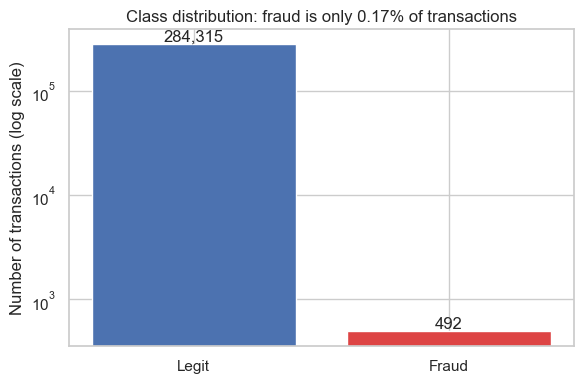

In [4]:
counts = df["Class"].value_counts().rename({0: "Legit", 1: "Fraud"})
print(counts)
print(f"Fraud rate: {counts['Fraud'] / counts.sum():.3%}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[COLORS["Legit"], COLORS["Fraud"]])
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution: fraud is only 0.17% of transactions")
save_fig("01_class_distribution")

The y-axis is on a log scale. Without it, the fraud bar would be too small to see.

## 4. Transaction amounts

In [5]:
df.groupby("Class")["Amount"].describe().rename(index={0: "Legit", 1: "Fraud"}).round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legit,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


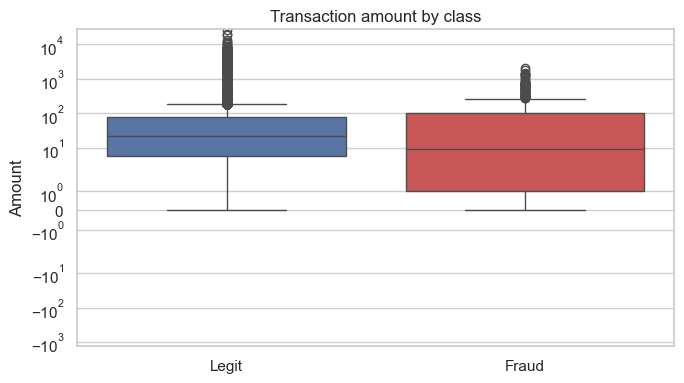

In [6]:
plot_df = df.assign(Label=df["Class"].map({0: "Legit", 1: "Fraud"}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=plot_df, x="Label", y="Amount", hue="Label", palette=COLORS, ax=ax, legend=False)
ax.set_yscale("symlog")
ax.set_xlabel("")
ax.set_title("Transaction amount by class")
save_fig("02_amount_by_class")

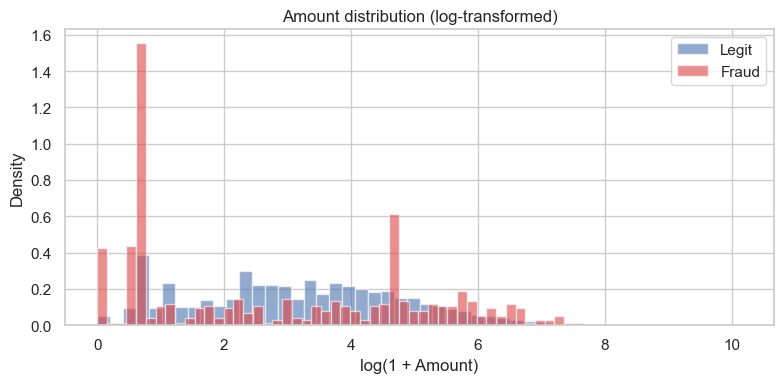

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, color in COLORS.items():
    subset = plot_df.loc[plot_df["Label"] == label, "Amount"]
    ax.hist(np.log1p(subset), bins=50, alpha=0.6, density=True, color=color, label=label)
ax.set_xlabel("log(1 + Amount)")
ax.set_ylabel("Density")
ax.set_title("Amount distribution (log-transformed)")
ax.legend()
save_fig("03_amount_distribution")

Fraudulent transactions are usually small, often just a few units. Fraudsters tend to test a stolen card with small
purchases first. So the amount alone can't separate fraud from legitimate transactions.

## 5. Which features relate to fraud?

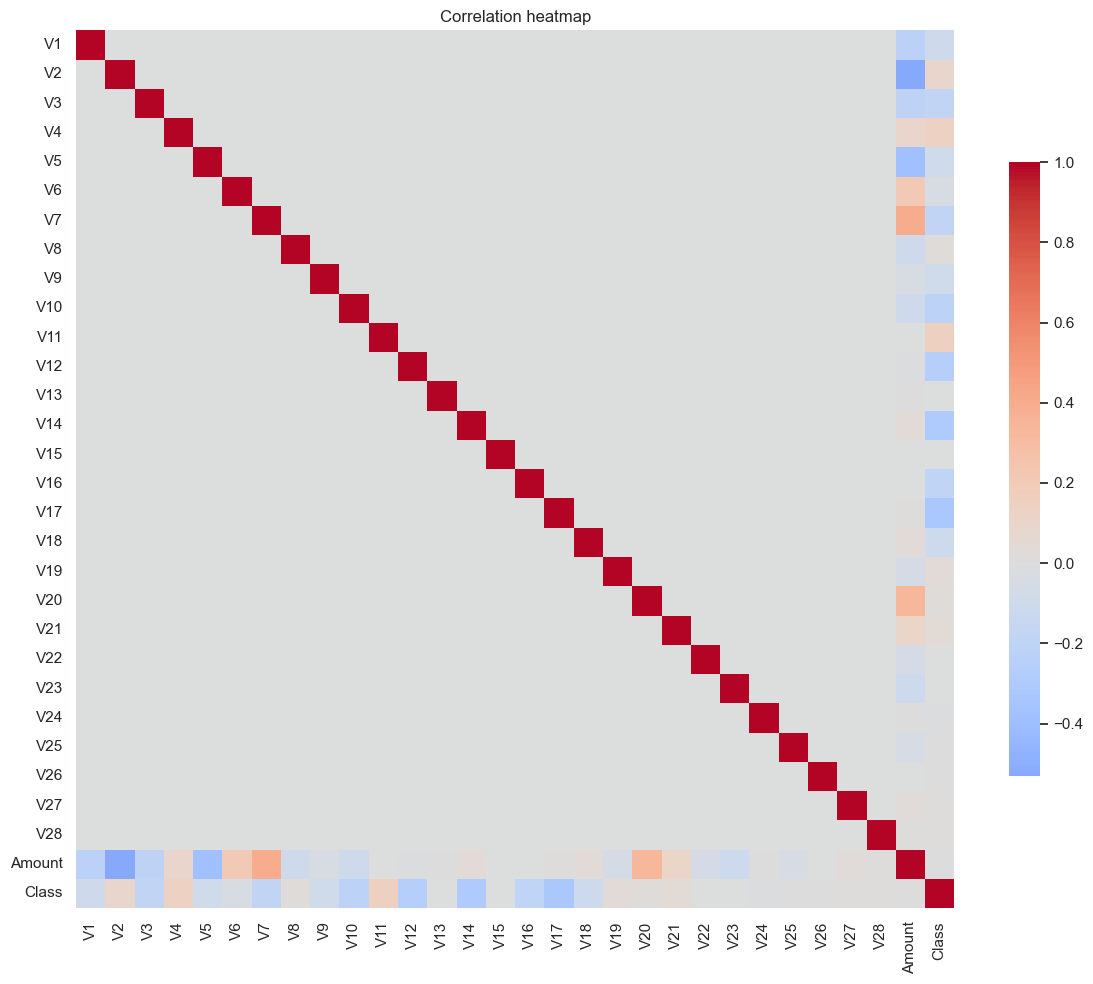

In [8]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlation heatmap")
save_fig("04_correlation_heatmap")

`V1`â€“`V28` barely correlate with each other. That's expected, because PCA produces uncorrelated components. The
interesting part is the last row: how each feature relates to `Class`.

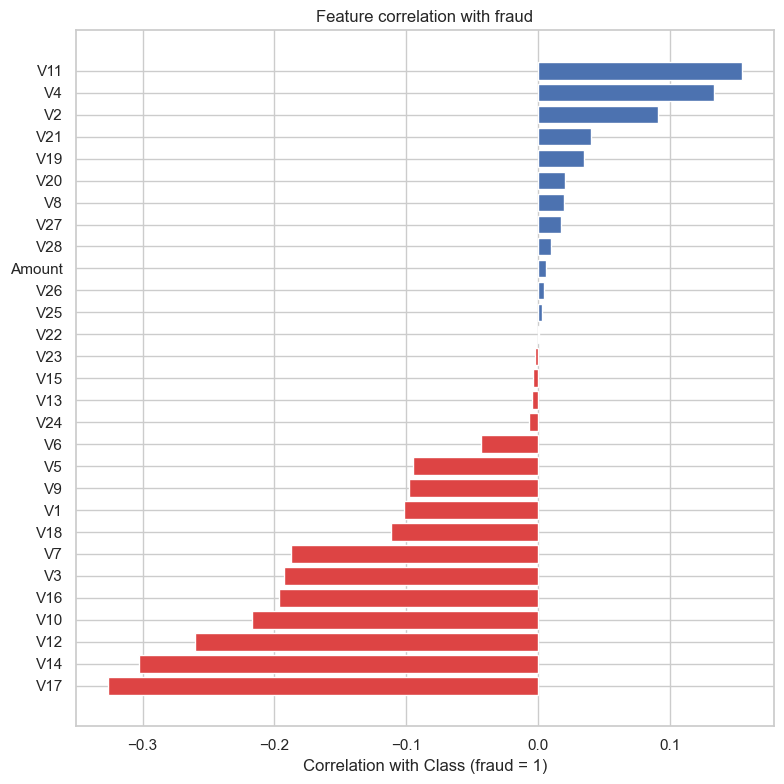

In [9]:
class_corr = corr["Class"].drop("Class").sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
colors = [COLORS["Fraud"] if v < 0 else COLORS["Legit"] for v in class_corr]
ax.barh(class_corr.index, class_corr.values, color=colors)
ax.set_xlabel("Correlation with Class (fraud = 1)")
ax.set_title("Feature correlation with fraud")
save_fig("05_feature_correlation_with_fraud")

Most fraud-related features: ['V17', 'V14', 'V12', 'V10']


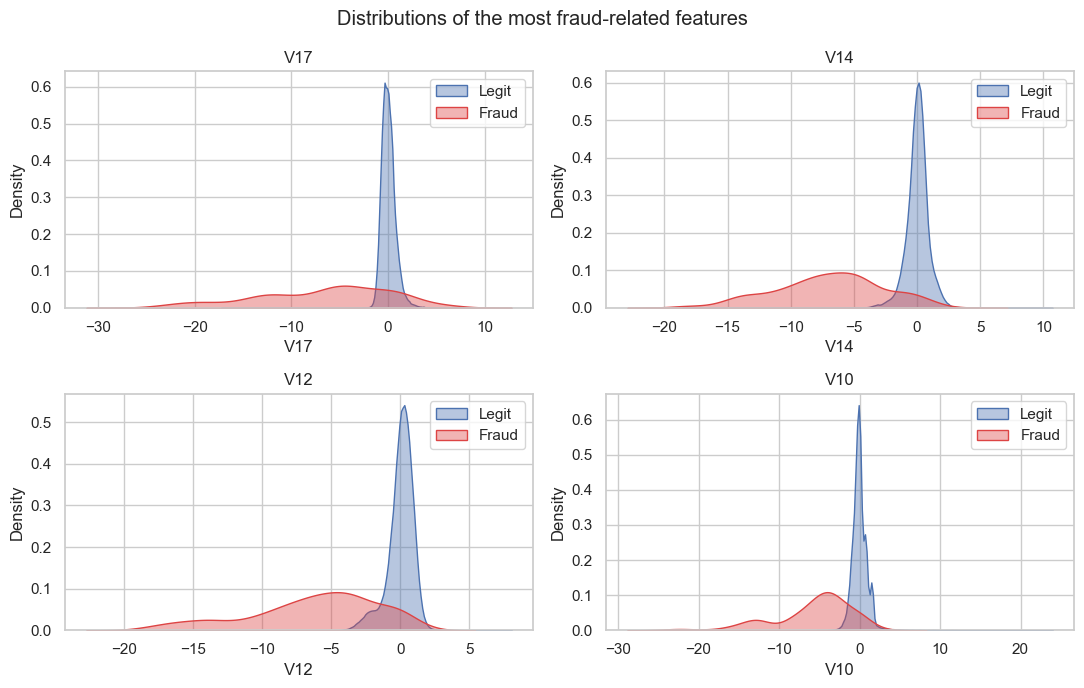

In [10]:
top_features = class_corr.abs().sort_values(ascending=False).head(4).index.tolist()
print("Most fraud-related features:", top_features)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.flat, top_features):
    for label, color in COLORS.items():
        sns.kdeplot(plot_df.loc[plot_df["Label"] == label, feature], ax=ax, color=color,
                    fill=True, alpha=0.4, label=label, common_norm=False, warn_singular=False)
    ax.set_title(feature)
    ax.legend()
fig.suptitle("Distributions of the most fraud-related features")
save_fig("06_top_feature_distributions")

For these features, fraud and legitimate transactions form clearly different shapes. That's a good sign that a model
can learn to separate them.

## 6. Prepare the data

1. **Remove duplicate rows**, so the same transaction can't appear in both the training and test sets. That would
   let the model "remember" answers and make its results look better than they are.
   This copy of the dataset has no `Time` column, so some of these duplicates may be different transactions that
   happen to look identical. Dropping them is the cautious choice.
2. **Stratified train/test split (80/20).** "Stratified" keeps the 0.17% fraud rate the same in both parts.
3. **Scale the features** with `StandardScaler`. `Amount` ranges from 0 to over 25,000 while the V features are
   around 0, and Logistic Regression works better when features are on a similar scale.

In [11]:
df_model = df.drop_duplicates()
print(f"Removed {len(df) - len(df_model):,} duplicate rows -> {len(df_model):,} rows for modelling")

X = df_model.drop(columns="Class")
y = df_model["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows ({y_train.sum()} fraud)")
print(f"Test:  {len(X_test):,} rows ({y_test.sum()} fraud)")

Removed 9,144 duplicate rows -> 275,663 rows for modelling


Train: 220,530 rows (378 fraud)
Test:  55,133 rows (95 fraud)


## 7. Handling the imbalance with SMOTE

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new, synthetic fraud examples. It picks a fraud
transaction, finds its nearest fraud "neighbours", and creates new points on the lines between them. The model then
sees enough fraud examples to learn what fraud looks like.

**Important:** SMOTE is applied **only to the training data**, inside a pipeline. The test set stays untouched and
realistic (0.17% fraud), so our evaluation reflects real-world conditions.

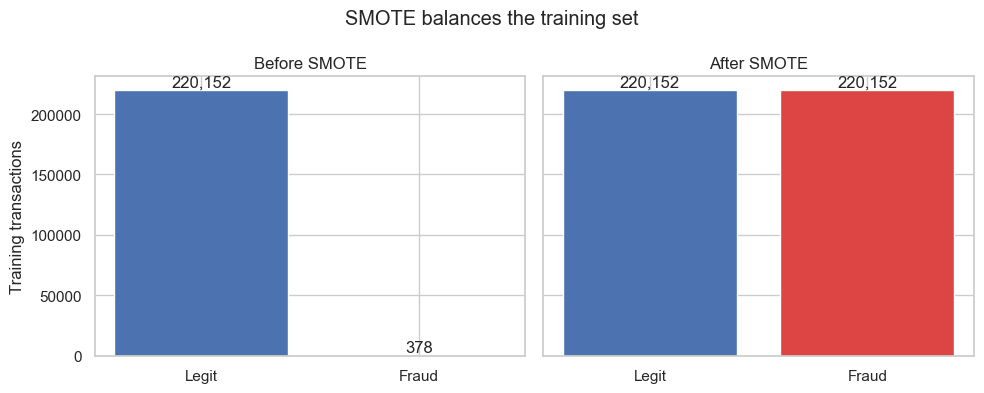

In [12]:
X_train_scaled = StandardScaler().fit_transform(X_train)
_, y_train_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_scaled, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_train_smote).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, data, title in [(axes[0], before, "Before SMOTE"), (axes[1], after, "After SMOTE")]:
    bars = ax.bar(["Legit", "Fraud"], data.values, color=[COLORS["Legit"], COLORS["Fraud"]])
    ax.bar_label(bars, labels=[f"{v:,}" for v in data.values])
    ax.set_title(title)
axes[0].set_ylabel("Training transactions")
fig.suptitle("SMOTE balances the training set")
save_fig("07_smote_resampling")

### Does SMOTE actually help?

Let's compare the same Logistic Regression model with and without SMOTE.

In [13]:
def make_pipeline(model, use_smote=True):
    steps = [("scaler", StandardScaler())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)


smote_comparison = []
for use_smote in [False, True]:
    pipe = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), use_smote)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    smote_comparison.append({
        "Setup": "With SMOTE" if use_smote else "Without SMOTE",
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Frauds caught": f"{((pred == 1) & (y_test == 1)).sum()} / {y_test.sum()}",
    })

pd.DataFrame(smote_comparison).round(3)

,Setup,Recall,Precision,Frauds caught
0,Without SMOTE,0.568,0.857,54 / 95
1,With SMOTE,0.895,0.057,85 / 95


With SMOTE the model catches far more frauds (higher recall), but it also raises more false alarms (lower precision).
That's the core trade-off in fraud detection: a missed fraud usually costs the bank more than an extra alert that a
human reviews.

## 8. Train and compare three models

- **Logistic Regression:** a simple, fast, easy-to-explain linear model. A good baseline.
- **Decision Tree:** learns yes/no rules (e.g. "if V14 < -5 then fraud"). Easy to read, but tends to overfit.
- **Random Forest:** many decision trees, each trained on a random sample of rows and features, voting together.
  Usually much more accurate than a single tree.

All three use the same pipeline: scale â†’ SMOTE â†’ model.

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
}

fitted, predictions, probabilities, results = {}, {}, {}, []
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    fitted[name], predictions[name], probabilities[name] = pipe, pred, proba
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })
    print(f"Trained {name}")

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

Trained Logistic Regression


Trained Decision Tree


Trained Random Forest


,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
Logistic Regression,0.057,0.895,0.107,0.978,0.689
Decision Tree,0.363,0.737,0.486,0.867,0.268
Random Forest,0.830,0.768,0.798,0.961,0.816


**How to read these metrics**
- **Precision:** of the transactions we flagged as fraud, how many really were fraud.
- **Recall:** of all the real frauds, how many we caught.
- **F1:** a single score that balances precision and recall.
- **ROC-AUC:** how well the model ranks fraud above legitimate transactions (1.0 = perfect, 0.5 = random guessing).
  It can look very high on imbalanced data, so we also check...
- **PR-AUC (average precision):** the same idea, but focused on the fraud class. This is the fairest single
  metric for heavily imbalanced data.

## 9. Confusion matrices

A confusion matrix shows four counts: frauds caught (true positives), frauds missed (false negatives), false alarms
(false positives) and correctly ignored legitimate transactions (true negatives).

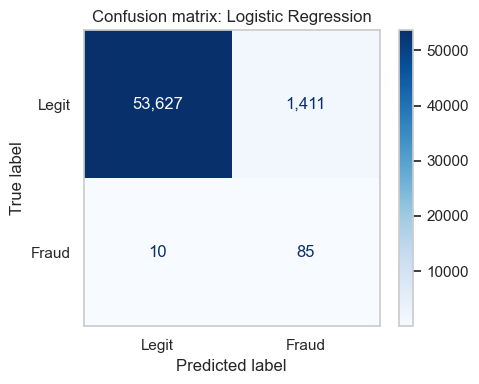

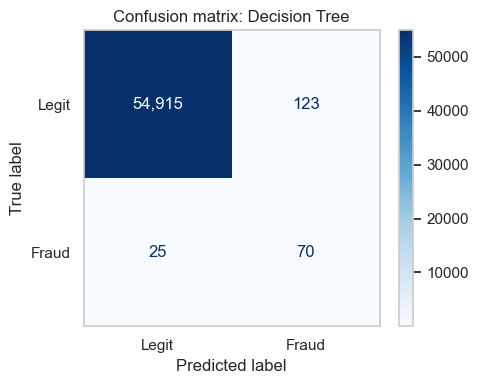

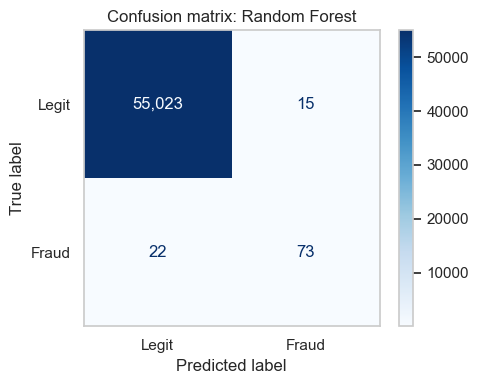

In [15]:
for i, name in enumerate(models, start=8):
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], display_labels=["Legit", "Fraud"], cmap="Blues", values_format=",", ax=ax
    )
    ax.set_title(f"Confusion matrix: {name}")
    ax.grid(False)
    save_fig(f"{i:02d}_confusion_matrix_{name.lower().replace(' ', '_')}")

## 10. ROC and precision-recall curves

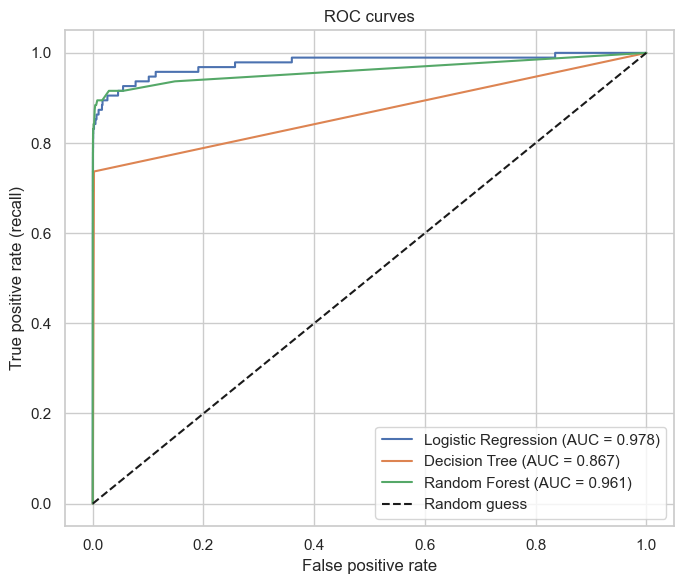

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
save_fig("11_roc_curves")

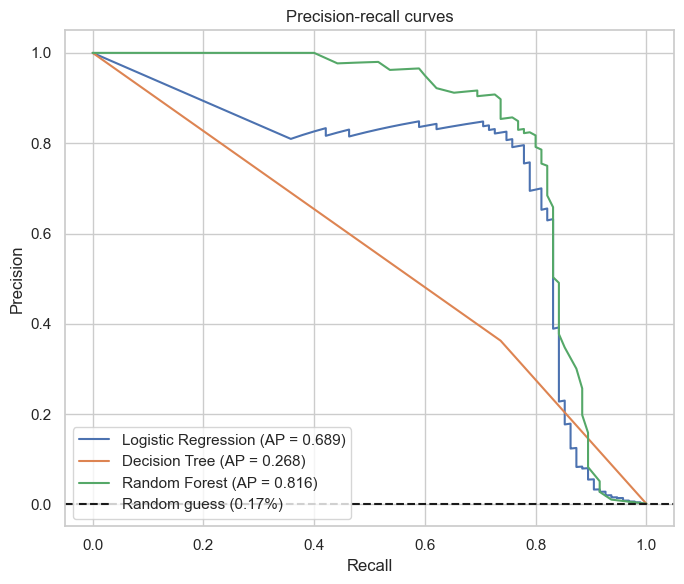

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ax.plot(recall, precision, label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
ax.axhline(y_test.mean(), color="k", linestyle="--", label=f"Random guess ({y_test.mean():.2%})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves")
ax.legend(loc="lower left")
save_fig("12_precision_recall_curves")

## 11. Which features matter most?

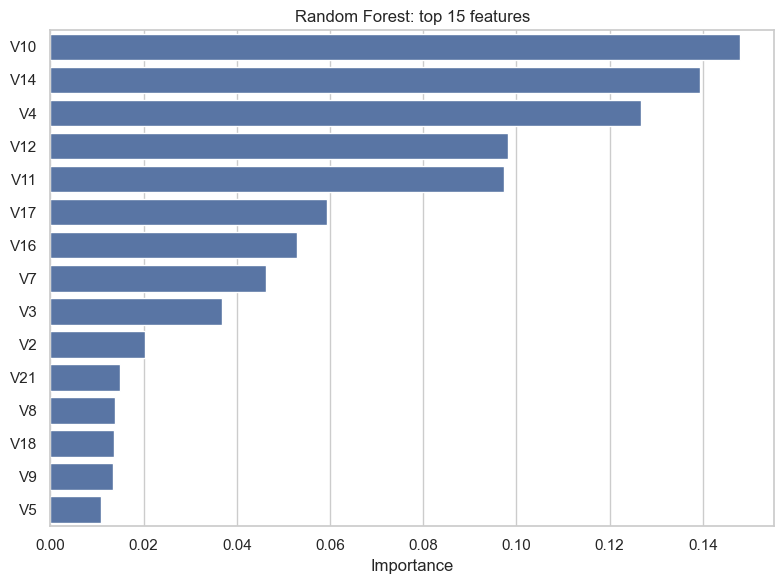

In [18]:
rf = fitted["Random Forest"].named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importance.values, y=importance.index, color=COLORS["Legit"], ax=ax)
ax.set_xlabel("Importance")
ax.set_ylabel("")
ax.set_title("Random Forest: top 15 features")
save_fig("13_feature_importance")

Most of the top features (`V10`, `V14`, `V12`, `V17`) are the same ones that were most correlated with fraud in the
EDA (section 5). This consistency is a good sign that the model is learning real patterns.

## 12. Choosing the alert threshold

By default a transaction is flagged when the fraud probability is at least 0.5. A bank can move this threshold:
lower means catching more fraud but more false alarms, higher means fewer alarms but more missed frauds.

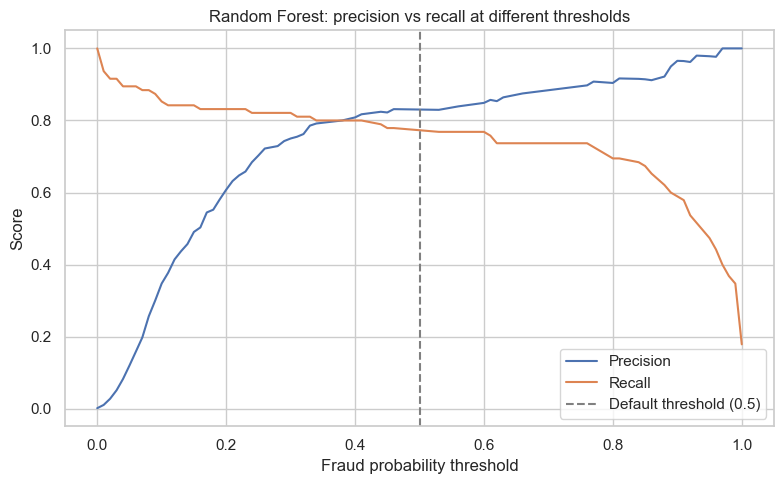

In [19]:
rf_proba = probabilities["Random Forest"]
precision, recall, thresholds = precision_recall_curve(y_test, rf_proba)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.axvline(0.5, color="grey", linestyle="--", label="Default threshold (0.5)")
ax.set_xlabel("Fraud probability threshold")
ax.set_ylabel("Score")
ax.set_title("Random Forest: precision vs recall at different thresholds")
ax.legend()
save_fig("14_threshold_tradeoff")

## 13. SQL analysis: flagging high-risk transactions

A bank's fraud team typically works with a database, not a notebook. So we load the Random Forest's predictions on
the test set into a **SQLite** database and answer business questions with SQL.

In [20]:
scored = pd.DataFrame({
    "txn_id": X_test.index,
    "amount": X_test["Amount"].values,
    "actual_fraud": y_test.values,
    "fraud_probability": rf_proba.round(4),
    "predicted_fraud": predictions["Random Forest"],
})

conn = sqlite3.connect(":memory:")
scored.to_sql("transactions", conn, index=False)


def sql(query):
    return pd.read_sql_query(query, conn)


print(f"Loaded {len(scored):,} scored test transactions into SQLite")

Loaded 55,133 scored test transactions into SQLite


### Q1. How many frauds did we catch, miss, and how many false alarms did we raise?

In [21]:
sql("""
SELECT
    SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 1 THEN 1 ELSE 0 END) AS frauds_caught,
    SUM(CASE WHEN predicted_fraud = 0 AND actual_fraud = 1 THEN 1 ELSE 0 END) AS frauds_missed,
    SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 0 THEN 1 ELSE 0 END) AS false_alarms,
    ROUND(100.0 * SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 0 THEN 1 ELSE 0 END)
          / SUM(CASE WHEN actual_fraud = 0 THEN 1 ELSE 0 END), 4) AS false_alarm_rate_pct,
    ROUND(100.0 * SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 0 THEN 1 ELSE 0 END)
          / SUM(predicted_fraud), 2) AS pct_of_alerts_that_are_false
FROM transactions
""")

,frauds_caught,frauds_missed,false_alarms,false_alarm_rate_pct,pct_of_alerts_that_are_false
0,73,22,15,0.0273,17.05


### Q2. The 10 highest-risk transactions for the fraud team to review first

In [22]:
sql("""
SELECT txn_id, amount, fraud_probability, actual_fraud
FROM transactions
WHERE fraud_probability >= 0.9
ORDER BY fraud_probability DESC, amount DESC
LIMIT 10
""")

,txn_id,amount,fraud_probability,actual_fraud
0,150662,316.06,1.0,1
1,64460,99.99,1.0,1
2,15166,99.99,1.0,1
3,15781,99.99,1.0,1
4,15539,99.99,1.0,1
5,17366,99.99,1.0,1
6,16415,23.36,1.0,1
7,27627,18.96,1.0,1
8,96994,7.53,1.0,1
9,88897,1.10,1.0,1


### Q3. Fraud rate and model performance by transaction amount band

In [23]:
sql("""
SELECT
    CASE
        WHEN amount < 10 THEN '1. under 10'
        WHEN amount < 100 THEN '2. 10 - 100'
        WHEN amount < 500 THEN '3. 100 - 500'
        ELSE '4. 500+'
    END AS amount_band,
    COUNT(*) AS transactions,
    SUM(actual_fraud) AS actual_frauds,
    ROUND(100.0 * SUM(actual_fraud) / COUNT(*), 3) AS fraud_rate_pct,
    SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 1 THEN 1 ELSE 0 END) AS frauds_caught,
    SUM(CASE WHEN predicted_fraud = 1 AND actual_fraud = 0 THEN 1 ELSE 0 END) AS false_alarms
FROM transactions
GROUP BY amount_band
ORDER BY amount_band
""")

,amount_band,transactions,actual_frauds,fraud_rate_pct,frauds_caught,false_alarms
0,1. under 10,18262,50,0.274,35,7
1,2. 10 - 100,25541,21,0.082,19,4
2,3. 100 - 500,9414,16,0.170,14,3
3,4. 500+,1916,8,0.418,5,1


### Q4. If the team can only review the riskiest 1% of transactions, how much fraud do they find?

This uses **window functions**: `NTILE(100)` splits transactions into 100 equal groups by risk, and `SUM() OVER`
builds a running total of fraud found.

In [24]:
sql("""
WITH ranked AS (
    SELECT actual_fraud,
           NTILE(100) OVER (ORDER BY fraud_probability DESC) AS risk_percentile
    FROM transactions
),
by_percentile AS (
    SELECT risk_percentile, SUM(actual_fraud) AS frauds
    FROM ranked
    GROUP BY risk_percentile
)
SELECT
    risk_percentile AS top_pct_reviewed,
    SUM(frauds) OVER (ORDER BY risk_percentile) AS cumulative_frauds_found,
    ROUND(100.0 * SUM(frauds) OVER (ORDER BY risk_percentile)
          / (SELECT SUM(actual_fraud) FROM transactions), 1) AS pct_of_all_fraud_found
FROM by_percentile
ORDER BY risk_percentile
LIMIT 5
""")

,top_pct_reviewed,cumulative_frauds_found,pct_of_all_fraud_found
0,1,85,89.5
1,2,86,90.5
2,3,87,91.6
3,4,87,91.6
4,5,87,91.6


### Q5. Missed frauds that were larger than the average fraud amount

These are the most expensive mistakes. This query uses a **subquery** to compare each amount against the average.

In [25]:
sql("""
SELECT txn_id, amount, fraud_probability
FROM transactions
WHERE actual_fraud = 1
  AND predicted_fraud = 0
  AND amount > (SELECT AVG(amount) FROM transactions WHERE actual_fraud = 1)
ORDER BY amount DESC
""")

,txn_id,amount,fraud_probability
0,176049,2125.87,0.03
1,233258,996.27,0.44
2,151196,571.48,0.09
3,145800,451.27,0.10


In [26]:
conn.close()

## 14. Conclusions

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.057 | 0.895 | 0.107 | 0.978 | 0.689 |
| Decision Tree | 0.363 | 0.737 | 0.486 | 0.867 | 0.268 |
| **Random Forest** | **0.830** | 0.768 | **0.798** | 0.961 | **0.816** |

- **SMOTE raised Logistic Regression's recall from 0.568 to 0.895** (from 54 to 85 of the 95 test frauds caught),
  at the cost of many more false alarms.
- **Random Forest is the best overall model.** It has the highest F1 and PR-AUC, catching 73 of 95 frauds with only
  15 false alarms out of 55,038 legitimate transactions (a 0.027% false alarm rate).
- **Logistic Regression has the highest ROC-AUC (0.978)** and the highest recall, but at a 0.5 threshold about 94%
  of its alerts are false. This shows why ROC-AUC alone is misleading on imbalanced data, and why PR-AUC matters.
- **The Decision Tree overfits.** A single deep tree memorises the synthetic SMOTE points and generalises poorly.
- **Reviewing the riskiest 1% of transactions finds 89.5% of all fraud** (SQL query Q4), which gives a fraud team
  a practical way to prioritise its work.
- `V10`, `V14`, `V12` and `V17` are strong fraud signals in both the correlation analysis and the Random Forest
  feature importance. The forest also relies heavily on `V4` and `V11`, which it combines with other features.

**Possible next steps:** tune the threshold to the bank's cost of a missed fraud vs. a false alarm, try gradient
boosting (XGBoost / LightGBM), and use cross-validation for more stable estimates.